# Las antorchas: la llama que se ve desde el espacio

Los notebooks 01 y 02 miran la luz visible: una locación es un rectángulo claro. Acá se miran las bandas
infrarrojas de la misma escena mensual. Una chimenea de quema encendida es de lo poco que, en la meseta,
emite por sí mismo en el infrarrojo de onda corta: a 20 metros por píxel se ve como un punto que satura.

La pregunta es la misma de siempre: qué se puede saber con datos abiertos, y cuánto coincide con el
registro oficial. La Secretaría de Energía publica los puntos de venteo que declaran las empresas; se
comparan al final.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path.cwd().parent / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display
from loclab import ZONAS, DATA_PROC, DATA_RAW, FIGURES
from loclab import antorchas, padron, figuras
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
FIGURES.mkdir(parents=True, exist_ok=True); DATA_PROC.mkdir(parents=True, exist_ok=True)
zonas = sorted(z for z in ZONAS if list((DATA_RAW / z / "swir").glob("20*.npz")))
print(len(zonas), "zonas con bandas infrarrojas:", sum(len(list((DATA_RAW / z / "swir").glob("20*.npz"))) for z in zonas), "escenas mensuales")

15 zonas con bandas infrarrojas: 1220 escenas mensuales


## 1. Un píxel caliente

Tres bandas de 20 m: el infrarrojo cercano (B8A, 0,86 micrones) y las dos de onda corta (B11 en 1,6 y B12
en 2,2). El suelo desnudo de la meseta refleja parecido en las tres. Una llama no refleja: emite, y emite
más cuanto más larga la onda. Por eso B12 queda muy por encima de B11 y de B8A. El índice es el de Liu
et al. (2021): TAI = (B12 − B11) / B8A, y se pide además que el exceso y el brillo sean altos.

In [2]:
m = antorchas.cargar_mes("loma_campana_este", "2026-07")
cal = antorchas.calientes(m["b12"], m["b11"], m["b8a"])
t = pd.DataFrame({"": ["píxeles calientes", "el resto de la ventana"],
                  "píxeles": [int(cal.sum()), int((~cal).sum())],
                  "B8A": [np.median(m["b8a"][cal]), np.median(m["b8a"][~cal])],
                  "B11": [np.median(m["b11"][cal]), np.median(m["b11"][~cal])],
                  "B12": [np.median(m["b12"][cal]), np.median(m["b12"][~cal])]}).set_index("")
print("Loma Campana este,", m["fecha"], "· reflectancia mediana por banda")
display(t.round(2))
print(f"umbral: TAI >= {antorchas.TAI_MIN}, B12 - B11 >= {antorchas.EXCESO_MIN}, B12 >= {antorchas.B12_MIN}")

Loma Campana este, 2026-07-05 · reflectancia mediana por banda


,píxeles,B8A,B11,B12
,,,,
píxeles calientes,49,0.22,0.41,0.83
el resto de la ventana,616151,0.17,0.19,0.18


umbral: TAI >= 0.45, B12 - B11 >= 0.05, B12 >= 0.15


## 2. Buscar en toda la serie

Los píxeles calientes de cada escena se agrupan, y los grupos que caen en el mismo lugar (a menos de 100 m)
en meses distintos forman un foco. Una escena por mes, de 2020 a 2026, en las quince ventanas.

In [3]:
det = pd.concat([antorchas.detectar(z) for z in zonas], ignore_index=True)
focos = antorchas.resumir(det)
print(f"{len(det)} detecciones · {len(focos)} focos · {int((focos.meses >= antorchas.MESES_MIN).sum())} vistos en tres meses o más")
rep = focos[focos.meses >= antorchas.MESES_MIN].groupby("zona").size().rename("focos en 3+ meses").sort_values(ascending=False)
display(rep.to_frame().T)

4420 detecciones · 756 focos · 263 vistos en tres meses o más


zona,loma_campana_oeste,ypf_sur_este,aguada_pichana_oeste,norte_lac_bdp_bandurria,sierras_blancas,loma_campana_este,aguada_pichana_este,fortin_de_piedra,norte_este,norte_norte,aguada_del_chanar,norte_noreste,rincon_del_mangrullo,loma_la_lata_sur,aguada_pichana_norte
focos en 3+ meses,101,29,16,16,16,16,13,13,10,10,6,6,5,4,2


## 3. El problema: no todo lo que brilla es una llama

Loma Campana oeste da cuatro veces más focos que cualquier otra ventana. Es la que incluye a Añelo. Lo que
se enciende ahí no son antorchas: son techos de chapa y galpones, que con el sol bajo del invierno reflejan
en el infrarrojo de onda corta lo suficiente para pasar el umbral. Se delatan por el calendario: una llama
se ve en cualquier mes; un reflejo, casi solo de mayo a agosto.

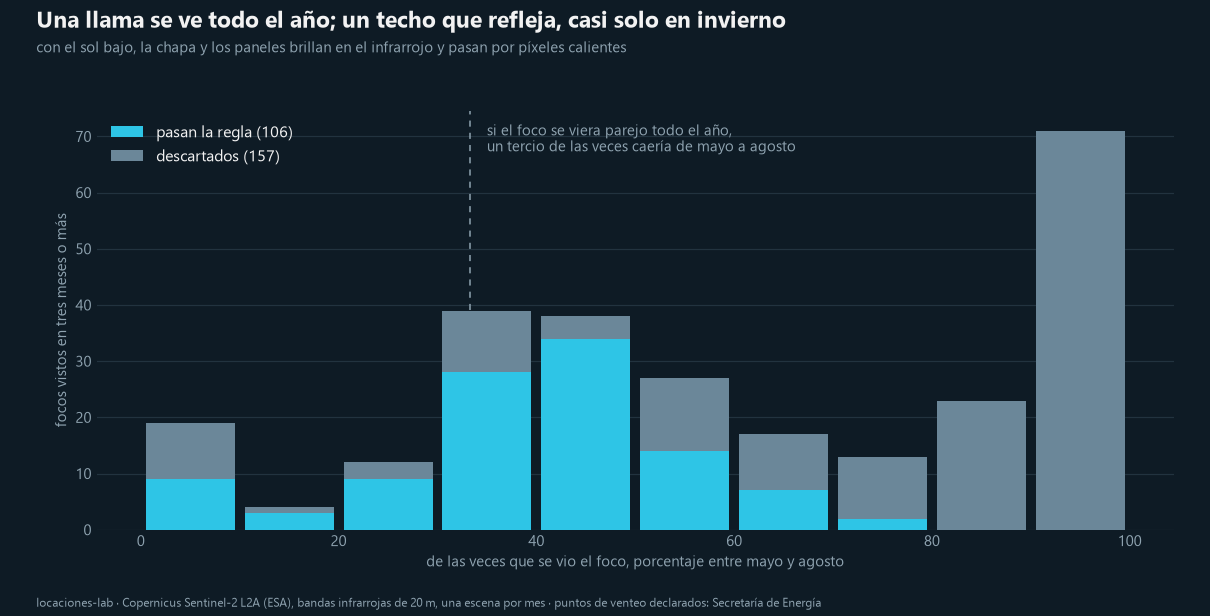

In [4]:
display(Image(figuras.antorchas_invierno(focos, det, FIGURES / "antorchas_invierno.png")))

## 4. La regla

Un foco es una antorcha si se lo vio en tres escenas o más, tres de ellas fuera del invierno, si la banda de
2,2 micrones satura alguna vez y si está a más de 3 km de Añelo (el mismo filtro que usa el detector de
locaciones). Las ventanas vecinas se pisan en el borde: de dos antorchas a menos de 200 m queda una.

In [5]:
f3 = focos[focos.meses >= antorchas.MESES_MIN]
pasos = pd.DataFrame({"focos": [len(f3), int((f3.fuera_invierno >= antorchas.FUERA_INVIERNO_MIN).sum()),
                                int(((f3.fuera_invierno >= antorchas.FUERA_INVIERNO_MIN) & (f3.b12 >= antorchas.B12_SATURA)).sum()),
                                int(focos.antorcha.sum())]},
                     index=["vistos en tres meses o más", "y tres o más fuera del invierno", "y que saturan alguna vez", "y a más de 3 km de Añelo"])
display(pasos)
ant = antorchas.unir(focos)
print(len(ant), "antorchas sin repetir entre ventanas vecinas")

,focos
vistos en tres meses o más,263
y tres o más fuera del invierno,139
y que saturan alguna vez,119
y a más de 3 km de Añelo,106


94 antorchas sin repetir entre ventanas vecinas


### Y después, mirarlas una por una

La regla no alcanza. Se miró el recorte en color real de las que no tienen un punto de venteo declarado
cerca: seis eran galpones o bases de servicios junto a zonas urbanas, y dos no se pudieron ver porque la
escena estaba saturada. En un segundo repaso, con el mes de mancha más grande de cada una, salieron otras
tres: el techo de un galpón dentro de una planta, los reflejos de los techos de otra planta y una dudosa
de un solo píxel junto a chacras. Las once quedan afuera. La planilla está en `data/antorchas_revision.csv`.

In [6]:
rev = pd.read_csv("../data/antorchas_revision.csv")
ant = antorchas.aplicar_revision(ant, rev)
print(rev.veredicto.value_counts().to_dict())
firmes = ant[ant.firme].reset_index(drop=True)
print(len(firmes), "antorchas firmes")

{'galpon': 3, 'sin ver': 2, 'base de servicios': 2, 'zona urbana': 2, 'techos de planta': 1, 'dudosa': 1}
83 antorchas firmes


Así se ven las seis que más meses estuvieron encendidas: arriba el color real a 10 m, abajo las bandas
infrarrojas (B12, B11, B8A) a 20 m. La llama es el punto claro sobre la instalación.

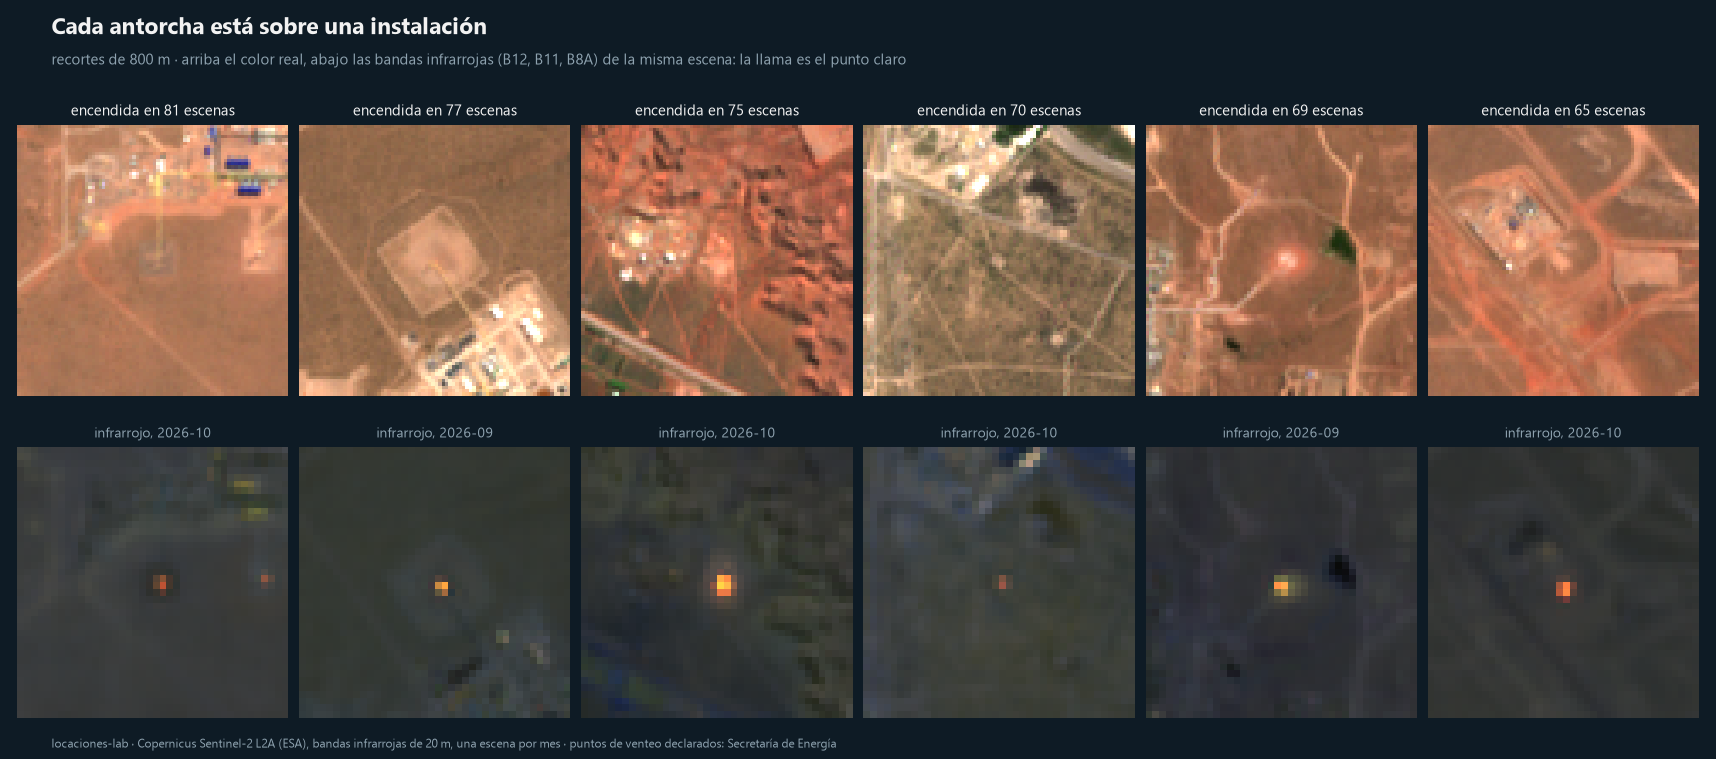

In [7]:
from rasterio.transform import Affine
top = firmes.sort_values("meses", ascending=False).head(6)
arriba, abajo, tit, meses_rec = [], [], [], []
for a in top.itertuples():
    mes = det[(det.zona == a.zona) & (det.foco == a.foco)].mes.max()
    e = np.load(DATA_RAW / a.zona / f"{mes}.npz"); m = antorchas.cargar_mes(a.zona, mes)
    rgb = np.dstack([e[k].astype(np.float32) / 10000 for k in ("red", "green", "blue")]); rgb = np.clip(rgb / np.median(rgb) * 0.42, 0, 1)
    c, f = ~Affine.from_gdal(*e["transform"]) * (a.x, a.y); c, f = int(c), int(f)
    c2, f2 = ~m["transform"] * (a.x, a.y); c2, f2 = int(c2), int(f2)
    sw = np.clip(np.dstack([m["b12"], m["b11"], m["b8a"]]) / 0.9, 0, 1)
    arriba.append(rgb[max(f - 40, 0):f + 40, max(c - 40, 0):c + 40]); abajo.append(sw[max(f2 - 20, 0):f2 + 20, max(c2 - 20, 0):c2 + 20])
    tit.append(f"encendida en {a.meses} escenas"); meses_rec.append(mes)
display(Image(figuras.antorchas_recortes(arriba, abajo, tit, meses_rec, FIGURES / "antorchas_recortes.png")))

## 5. Cuántas, dónde y desde cuándo

anio,2020,2021,2022,2023,2024,2025,2026
antorchas,37,42,53,54,56,63,61


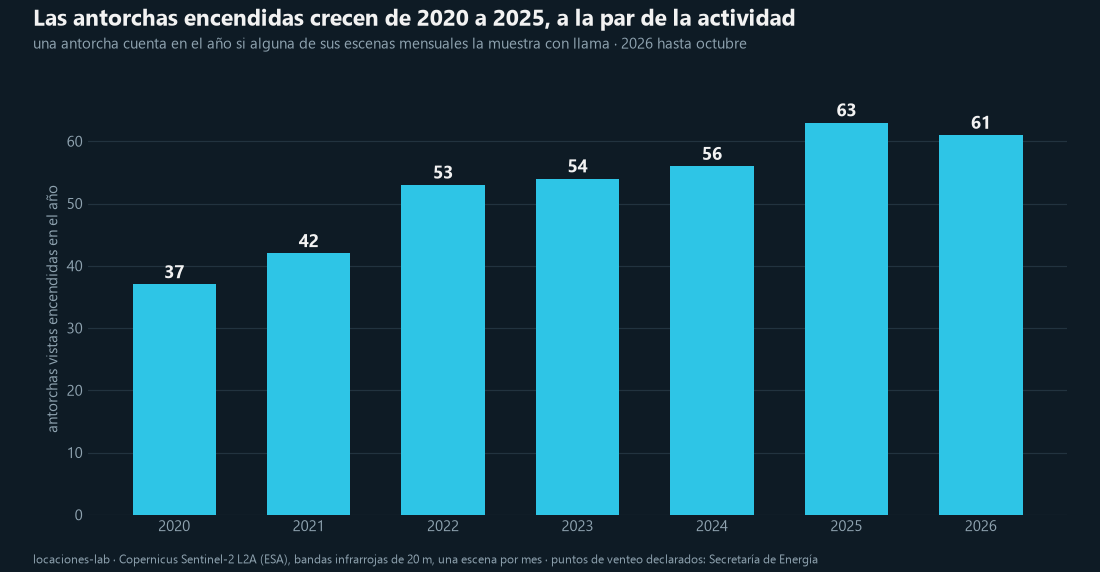

en la última escena (2026-10) estaban encendidas 24 de 83
mediana de escenas con llama por antorcha: 21 de 82


In [8]:
d = det.merge(firmes[["zona", "foco"]], on=["zona", "foco"])
d["anio"] = d.mes.str[:4].astype(int)
por_anio = d.groupby("anio").apply(lambda g: g[["zona", "foco"]].drop_duplicates().shape[0]).rename("antorchas").reset_index()
display(por_anio.set_index("anio").T)
display(Image(figuras.antorchas_por_anio(por_anio, FIGURES / "antorchas_por_anio.png")))
ult = sorted(det.mes.unique())[-1]
print(f"en la última escena ({ult}) estaban encendidas {d[d.mes == ult][['zona', 'foco']].drop_duplicates().shape[0]} de {len(firmes)}")
print("mediana de escenas con llama por antorcha:", int(firmes.meses.median()), "de 82")

## 6. Contra lo declarado

La Secretaría de Energía publica la ubicación de los puntos de venteo que declaran las empresas: chimeneas
y fosas de quema. Se cruza en los dos sentidos.

In [9]:
decl = antorchas.venteos_declarados()
firmes["km_declarado"] = antorchas.km_al_mas_cercano(firmes.lon, firmes.lat, decl.lon, decl.lat)
print(len(decl), "puntos declarados en el país")
print(f"de {len(firmes)} antorchas vistas: {int((firmes.km_declarado <= 0.15).sum())} tienen un punto declarado a menos de 150 m, "
      f"{int((firmes.km_declarado <= 0.5).sum())} a menos de 500 m y {int((firmes.km_declarado > 0.5).sum())} no tienen ninguno a menos de 500 m")
dentro = np.zeros(len(decl), bool)
for z in zonas:
    x0, y0, x1, y1 = ZONAS[z]["bbox"]; dentro |= decl.lon.between(x0, x1).values & decl.lat.between(y0, y1).values
dv = decl[dentro].copy()
dv["km_antorcha"] = antorchas.km_al_mas_cercano(dv.lon, dv.lat, firmes.lon, firmes.lat)
dv["vista"] = dv.km_antorcha <= 0.3
t = dv.groupby("tipo").vista.agg(declarados="size", con_antorcha_vista="sum")
t["porcentaje"] = (t.con_antorcha_vista / t.declarados * 100).round(0)
display(t)
sin = firmes[firmes.km_declarado > 0.5]
print(f"de las {len(sin)} sin punto declarado cerca: {int((sin.meses < 8).sum())} se vieron menos de 8 meses y {int((sin.meses >= 20).sum())} en 20 o más")
display(sin.groupby("zona").size().rename("sin punto declarado cerca").sort_values(ascending=False).to_frame().T)

1269 puntos declarados en el país
de 83 antorchas vistas: 42 tienen un punto declarado a menos de 150 m, 43 a menos de 500 m y 40 no tienen ninguno a menos de 500 m


,declarados,con_antorcha_vista,porcentaje
tipo,,,
CHIMENEA DE QUEMA,101,67,66.0
FOSA DE QUEMA,72,8,11.0


de las 40 sin punto declarado cerca: 9 se vieron menos de 8 meses y 17 en 20 o más


zona,aguada_pichana_oeste,sierras_blancas,loma_campana_oeste,norte_lac_bdp_bandurria,norte_este,norte_noreste,aguada_pichana_este,norte_norte,aguada_pichana_norte,loma_la_lata_sur,loma_campana_este
sin punto declarado cerca,8,5,4,4,4,3,3,3,2,2,2


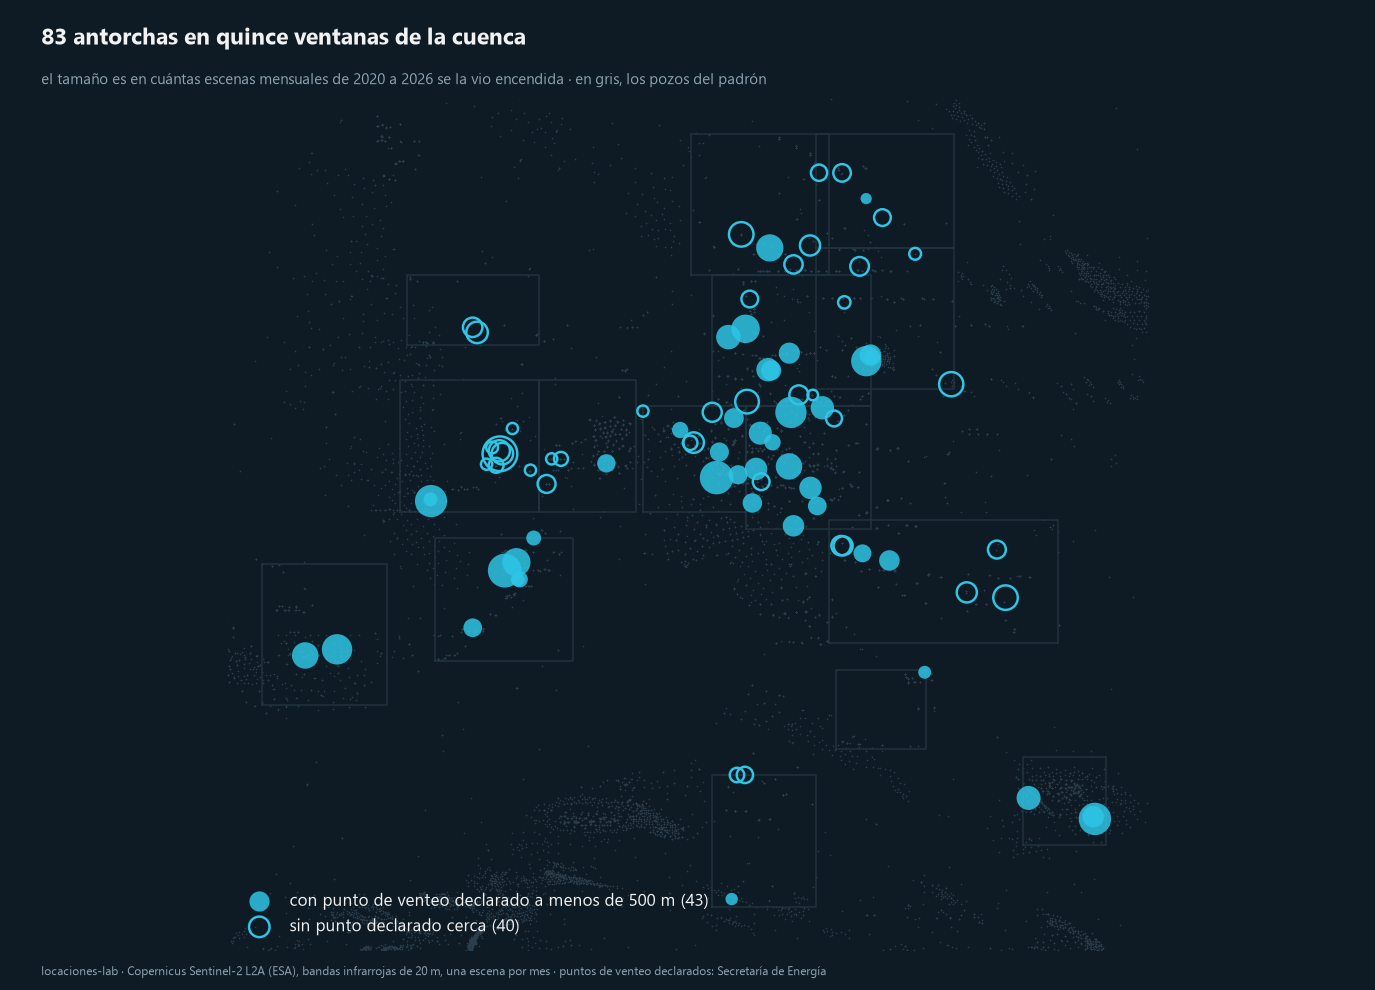

In [10]:
P = padron.pozos()
P = P[P.lon.between(-69.5, -68.1) & P.lat.between(-38.9, -37.9)]
display(Image(figuras.antorchas_mapa(firmes, P, {z: ZONAS[z] for z in zonas}, FIGURES / "antorchas_mapa.png")))

## 7. Qué se puede decir y qué no

- **El detector ubica bien.** La mitad de las antorchas cae a menos de 150 m de un punto declarado, y dos
  de cada tres chimeneas declaradas se vieron encendidas alguna vez.
- **Las que no tienen punto declarado cerca no son, por eso, irregulares.** Varias se vieron pocos meses y
  están sobre locaciones de pozo: una quema temporal de ensayo no lleva un punto fijo. Y en algunas áreas
  faltan casi todas, lo que apunta a un registro incompleto.
- **Se mira una escena por mes.** Una antorcha se prende y se apaga, y Sentinel-2 pasa cada dos o tres días:
  en un mes dado, la escena elegida pierde las que estuvieron encendidas otros días.
- **No se mide cuánto gas se quema.** Solo dónde y cuándo hay llama. Para el volumen hace falta un sensor
  nocturno (VIIRS) y el balance de gas declarado.
- **Las fosas de quema casi no se ven**: son intermitentes y más chicas.
- **La regla pierde algunas reales** que sí tienen un punto declarado al lado, por no saturar o por verse
  pocas veces fuera del invierno.

Los mismos resultados, como archivos, los deja `python scripts/antorchas.py` en `data/processed/`.